# 3장 1강 A/B 테스트 핵심 메커니즘과 실험 설계 오류 식별

## Intro

**과제 소개**
프로모션 A/B 데이터를 확인하고, 실험 결과를 신뢰하려면 어떤 조건을 점검해야 하는지 설명합니다. 교안의 개념을 이용해 **판단 → 사례 속 근거 → 이유 → 수정 방향**을 연결하는 것이 목표입니다.

**과제 목표**
- 대조군·실험군과 무작위 배정의 역할을 설명한다.
- 분석 단위·기간·핵심 지표·표본 크기를 구분한다.
- 신규성 효과·표본 오염·조기 종료·SRM을 사례의 근거로 진단한다.
- 핵심 지표와 중요한 보조 지표, 실험 조건을 함께 검토해 결론을 작성한다.

**구성**: 필수 1(중급 초입) → 필수 2(중급) → 과제 1(중급). **필수 1·2는 제출·채점 대상이 아니며, 과제 1만 제출·채점 대상**입니다.

**사용 툴/라이브러리**: Python, Jupyter Notebook, pandas, NumPy, matplotlib.

**학습 범위**: 판단에 필요한 개념은 교안의 1~4절을 사용합니다. 기본 pandas 집계·필터링은 기존 학습 내용을 활용하며, 새로운 통계 검정·표본 크기 계산·세그먼트 분석·수익 지표 설계는 요구하지 않습니다. 데이터 로딩과 그래프 코드는 제공합니다.

### 사용 데이터와 주요 컬럼

| 컬럼 | 의미 | 이번 실습에서의 사용 |
|---|---|---|
| LocationID | 매장 식별자 | 매장 수와 매장별 평균 계산 |
| Promotion | 프로모션 구분 | 1=A, 2=B로 가정; 3은 비교에서 제외 |
| week | 관측 주차 | 주차별 비교 |
| SalesInThousands | 천 단위로 기록된 매출 | 핵심 지표 계산 |
| MarketID / MarketSize / AgeOfStore | 시장·매장 특성 | 이번 실습에서는 분석하지 않음 |

### 분석에 필요한 설명 — 새로운 개념을 추론할 필요가 없도록 제공
- 실제 데이터는 `WA_Marketing-Campaign.csv`입니다. 같은 매장이 4주 동안 반복 기록되어 있습니다.
- 이 실습에서는 **매장을 배정·분석 단위**로 정합니다. 한 매장의 주차별 행이 여러 개여도 서로 다른 매장 여러 곳으로 세지 않습니다.
- 핵심 지표는 **매장별 4주 평균 주간 매출을 계산한 뒤, 그 값을 집단별로 평균한 값**입니다. 4주 누적 매출이 아닙니다.
- A는 기존 프로모션, B는 변경 프로모션이라는 **수업용 역할 가정**입니다. CSV가 실제 기존안·변경안을 알려주는 것은 아닙니다.
- 실제 배정 절차·예정 기간·목표 표본 수·예정 배정 비율은 CSV에 없습니다. 따라서 실제 데이터 문제와 별도로 **교육용 사례**의 조건을 명시합니다. 교육용 수치를 실제 WA 관측 결과와 섞지 않습니다.
- 무작위 배정은 각 대상이 정해진 확률로 배정되게 하는 절차입니다. 결과적인 집단 수가 반드시 같아야 한다는 뜻은 아닙니다.

**파일 구분: 정답 및 해설**

## 실습 준비 — 제공 코드
`DATA_PATH`에 직접 CSV 경로를 입력하거나 `None`을 유지하고 노트북 폴더·`data`·`upload`·`/content`에 CSV를 둡니다.
아래 코드는 A/B 데이터를 준비하고, 과제에서 사용할 매장별 평균 테이블도 만들어 줍니다. 원본의 Promotion을 새 라벨로 바꾸지 않습니다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
DATA_PATH = None
if DATA_PATH is not None:
    csv_path = Path(DATA_PATH).expanduser()
else:
    folders = [Path("."), Path("data"), Path("upload"), Path("/content"), Path("../data")]
    found = list(dict.fromkeys((p / "WA_Marketing-Campaign.csv").resolve()
                              for p in folders if (p / "WA_Marketing-Campaign.csv").is_file()))
    if len(found) != 1:
        raise FileNotFoundError(f"CSV 후보 {len(found)}개. DATA_PATH를 지정하세요. 후보: {found}")
    csv_path = found[0]
campaign = pd.read_csv(csv_path)
campaign_ab = campaign[campaign["Promotion"].isin([1, 2])].copy()
# 같은 매장의 4주 매출을 평균하여 한 매장을 한 행으로 정리합니다.
location_sales = (
    campaign_ab.groupby(["LocationID", "Promotion"], as_index=False)["SalesInThousands"]
    .mean().rename(columns={"SalesInThousands": "four_week_mean_sales"})
)
print("전체 데이터 크기:", campaign.shape)
print("A/B 데이터 크기:", campaign_ab.shape)
display(campaign_ab.head())
display(location_sales.head())

전체 데이터 크기: (548, 7)
A/B 데이터 크기: (360, 7)


,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
4,1,Medium,2,5,2,1,27.81
5,1,Medium,2,5,2,2,34.67
6,1,Medium,2,5,2,3,27.98
7,1,Medium,2,5,2,4,27.72
8,1,Medium,3,12,1,1,44.54


,LocationID,Promotion,four_week_mean_sales
0,2,2,29.5450
1,3,1,40.6800
2,4,2,33.7075
3,5,2,29.0025
4,7,1,43.2425


---
## 필수 1. 데이터에서 설계 4대 요소를 구분하기

<aside>
담당자가 “데이터 행 수가 많으니 표본이 충분하고, 두 집단의 수가 비슷하니 무작위 배정도 확인됐다”고 말했습니다. 데이터로 확인되는 사실과 계획서를 봐야 하는 사항을 구분하세요.
이 실습은 제출·채점 대상이 아닙니다.
</aside>

### 문제 1-1. 분석 단위와 무작위 배정 이해

**요구사항**
1. A/B 각각의 행 수와 고유 매장 수, 전체 관측 주차를 출력하세요. 대조군·실험군을 적고, 행 수와 매장 수 중 어느 것을 이번 실습의 표본 수로 사용할지 설명하세요.
2. 설계 4대 요소를 표로 정리하세요. 각 요소에 대해 **이번 분석의 정의 또는 관측값 / CSV만으로 확인하지 못한 사전 계획**을 적으세요. 관측된 4주를 사전에 계획한 4주로 단정하지 않습니다.
3. **다음 실험을 위한 배정 연습**으로 가상의 매장 100개를 A/B에 각각 0.5 확률로 배정하세요. 교안의 `np.random.seed(42)`, `np.random.choice()`를 사용하고 집단별 매장 수를 출력하세요. 정확히 50:50이어야 하는지 설명하세요. 실제 WA 매출에는 이 모의 라벨을 붙이지 않습니다.
4. 아래 Q1·Q2에 답하세요.

**Q&A**
- Q1. 집단별 매장 수가 비슷하면 실제 무작위 배정이 이루어졌다고 말할 수 있나요?
- Q2. 현재 관측된 매장 수만 보고 실험에 필요한 표본 수를 충분히 확보했다고 말할 수 있나요?

### 필수 1 · 요구사항 1 — 역할·표본 수·기간 확인

In [2]:
role = {1: "A (대조군·기존 프로모션)", 2: "B (실험군·변경 프로모션)"}
unit_check = (campaign_ab.groupby("Promotion")
              .agg(rows=("LocationID", "size"), stores=("LocationID", "nunique"),
                   weeks=("week", "nunique")))
unit_check.insert(0, "role", unit_check.index.map(role))
unit_check["rows_per_store"] = unit_check["rows"] / unit_check["stores"]
display(unit_check)
print("관측 주차:", sorted(int(w) for w in campaign_ab["week"].unique()))
print(f"합계: 행 {unit_check['rows'].sum()}개 / 매장 {unit_check['stores'].sum()}개")

,role,rows,stores,weeks,rows_per_store
Promotion,,,,,
1,A (대조군·기존 프로모션),172,43,4,4.0
2,B (실험군·변경 프로모션),188,47,4,4.0


관측 주차: [1, 2, 3, 4]
합계: 행 360개 / 매장 90개


**답안 작성**

- 계산·출력 결과:
  - A(Promotion 1, **대조군**): 행 172개 / 매장 **43개**
  - B(Promotion 2, **실험군**): 행 188개 / 매장 **47개**
  - 관측 주차는 1~4주차이고, 모든 매장이 4주씩 기록되어 있습니다(매장당 4행).
- 결과 해석 또는 판단 근거:
  - 표본 수로는 **매장 수(A 43, B 47)** 를 사용합니다. 배정과 분석의 단위가 매장이기 때문입니다.
  - 행 172·188개는 같은 매장을 주마다 반복해서 센 값입니다. 매장 43개 × 4주 = 172행이라서, 행 수를 표본 수로 쓰면 독립적인 관측이 4배 있는 것처럼 부풀려집니다.
  - 같은 매장의 1주차와 2주차 매출은 서로 비슷하게 움직이기 쉬우므로, 서로 다른 매장으로 볼 수 없습니다.

### 필수 1 · 요구사항 2 — 설계 4대 요소 표

**답안 작성**

- 판단 및 근거:

| 설계 요소 | 이번 분석의 정의 또는 관측값 | CSV만으로 확인하지 못한 사전 계획 |
|---|---|---|
| **분석(배정) 단위** | 매장(`LocationID`). 매장 1개 = 표본 1개 | 실제로 매장 단위로 배정했는지, 배정 절차가 무작위였는지 |
| **기간** | 관측된 기간은 1~4주차(4주) | 시작 전에 4주로 정했는지, 모든 매장이 같은 날 시작했는지, 도중에 멈추거나 늘렸는지 |
| **핵심 지표** | 매장별 4주 평균 주간 매출(천 단위)의 집단 평균 | 실험 시작 전에 이 지표를 핵심 지표로 정했는지, 함께 볼 보조 지표가 있었는지 |
| **표본 크기** | 관측된 매장 수: A 43개, B 47개(총 90개) | 목표 표본 수, 예정 배정 비율(예: 50:50), 표본 수를 어떤 기준으로 정했는지 |

- 수정 방향 또는 추가 확인 사항:
  - CSV에는 **결과 기록**만 있고 **실험 계획서**는 없습니다.
  - 실험 계획서(또는 배정 로그)에서 배정 방식, 예정 기간, 목표 표본 수, 예정 배정 비율, 사전에 정한 핵심 지표를 확인해야 합니다.
  - 확인하기 전까지 "관측된 4주 = 계획한 4주"라고 단정하지 않습니다.

### 필수 1 · 요구사항 3 — 교안 방식으로 무작위 배정 연습

In [3]:
np.random.seed(42)
practice_stores = np.arange(1, 101)
practice_group = np.random.choice(["A", "B"], size=len(practice_stores), p=[0.5, 0.5])
practice_assign = pd.DataFrame({"store": practice_stores, "group": practice_group})
print(practice_assign["group"].value_counts().sort_index())
display(practice_assign.head())

group
A    53
B    47
Name: count, dtype: int64


,store,group
0,1,A
1,2,B
2,3,B
3,4,B
4,5,A


**답안 작성**

- 계산·출력 결과: 가상 매장 100개를 0.5 확률로 한 번씩 배정한 결과, **A 53개 / B 47개**로 나뉘었습니다.
- 결과 해석 또는 판단 근거:
  - 정확히 50:50일 필요는 없습니다. 무작위 배정은 **각 매장이 A가 될 확률을 0.5로 정하는 절차**이지, 결과 개수를 똑같이 맞추는 규칙이 아니기 때문입니다.
  - 동전을 100번 던져도 앞면이 정확히 50번 나오는 경우는 드문 것과 같습니다. 53:47 정도는 확률적으로 자연스러운 변동입니다.
  - 이 라벨은 **다음 실험용 연습**일 뿐입니다. 실제 WA 매장 매출에는 붙이지 않습니다.

### 필수 1 · 요구사항 4 — Q&A

**답안 작성**

- 판단 및 근거:
  - **Q1.** 말할 수 없습니다. 무작위 배정은 **결과가 아니라 절차**입니다.
    - 담당자가 규모가 비슷한 매장끼리 골라서 나눠도 매장 수는 비슷하게 나옵니다. 반대로 요구사항 3처럼 제대로 무작위 배정해도 53:47처럼 차이가 날 수 있습니다.
    - 따라서 "매장 수가 비슷하다"는 무작위 배정의 증거가 되지 않습니다. 배정 방식(난수 사용 여부, 배정 시점, 배정 로그)을 직접 확인해야 합니다.
  - **Q2.** 말할 수 없습니다.
    - 표본이 충분한지는 **실험 전에 정한 목표 표본 수**(탐지하려는 최소 효과 크기 등을 바탕으로 정한 값)와 비교해야 판단할 수 있습니다.
    - CSV에는 그 목표가 없으므로, 관측된 매장 90개가 많은지 적은지 판단할 기준이 없습니다.
    - 담당자가 말한 "행 수가 많다"는 근거도, 같은 매장을 4번 센 값이라 표본 수가 아닙니다.
- 수정 방향 또는 추가 확인 사항: 실험 계획서의 목표 표본 수와 배정 절차를 확인하고, 보고서에는 "관측 매장 A 43개·B 47개"라고 **관측값으로만** 적습니다.

---
## 필수 2. 교안의 네 오류를 근거와 수정 방향으로 설명하기

<aside>
오류 이름만 맞히는 데서 끝내지 않습니다. 실제 주차별 매출을 읽고, 조건이 명시된 교육용 사례에서 판단 근거와 수정 방향을 제시하세요.
이 실습은 제출·채점 대상이 아닙니다.
</aside>

### 문제 2-1. 오류 식별과 결과 해석

**요구사항**
1. 제공 코드를 실행해 실제 WA 데이터의 주차별 A/B 평균 매출을 확인하고 `B−A`를 계산하세요. 1주차·4주차 차이를 제시하고, 이 추이만으로 신규성 효과를 확정할 수 있는지 설명하세요.
2. 아래 교육용 사례 N·C·E·S 각각에 대해 **오류 또는 의심 오류 / 사례 속 근거 / 결과 해석에 생기는 문제 / 수정·확인 방향**을 표로 작성하세요.
3. 실제 WA 데이터에 관해 네 오류 각각을 **확인한 사실 / 추가로 필요한 정보** 표로 정리하세요.
4. 아래 Q1·Q2에 답하세요.

### 교육용 사례 — 실제 WA 기록이 아닌 별도 상황

| 사례 | 판단을 위해 제공하는 조건 |
|---|---|
| N | 새 프로모션에 대한 반응을 관찰했다. A의 주차별 평균은 50, 50, 50, 50이고 B는 60, 55, 51, 50이었다. 담당자는 첫 주만 근거로 장기 개선 효과가 확정되었다고 말했다. |
| C | 한 매장을 고정 배정하지 않고 매주 다시 배정했다. 같은 매장이 1주차에는 A, 2주차에는 B를 실제 적용받았다. 담당자는 두 집단이 서로 다른 프로모션만 경험했다고 보고했다. |
| E | 시작 전에 4주간 관측하기로 했다. 담당자는 1주차에 B의 평균이 높게 나오자 그 결과를 이유로 종료하고 출시하려 한다. |
| S | 별도 온라인 실험에서 사용자별 A/B 배정 확률을 0.5씩 정했다. 실제 수집 데이터에는 서로 다른 사용자 A 6,500명, B 3,500명이 있었다. 담당자는 배정·수집 상태를 확인하지 않고 매출만 비교하려 한다. |

**Q&A**
- Q1. 실제 데이터에서 1주와 4주 모두 A의 평균이 높다면, 1주차에 종료했어도 설계상 문제가 없다고 말할 수 있나요?
- Q2. CSV에서 매장별 Promotion 종류 수가 하나이면 모든 표본 오염이 없었다고 말할 수 있나요?

### 필수 2 준비 — 집계·그래프·기록 점검 제공 코드
표의 `1`은 A, `2`는 B입니다.

Promotion,1,2
week,,
1,58.244,47.730
2,56.930,47.583
3,58.775,47.722
4,58.447,46.283


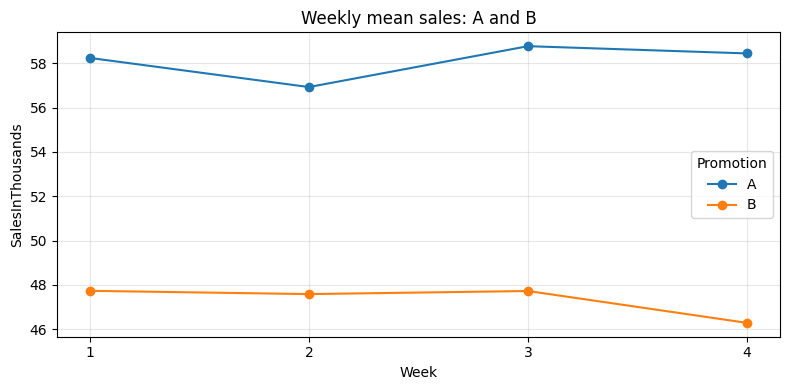

기록상 여러 Promotion이 있는 매장 수: 0


In [4]:
weekly_sales = (campaign_ab.groupby(["week", "Promotion"])["SalesInThousands"]
                .mean().unstack("Promotion").sort_index())
display(weekly_sales.round(3))
weekly_sales.rename(columns={1: "A", 2: "B"}).plot(marker="o", figsize=(8, 4))
plt.title("Weekly mean sales: A and B")
plt.xlabel("Week")
plt.ylabel("SalesInThousands")
plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# 원본 전체를 점검하여 Promotion 3으로 바뀐 기록도 놓치지 않습니다.
promotion_kinds = campaign.groupby("LocationID")["Promotion"].nunique()
print("기록상 여러 Promotion이 있는 매장 수:", int((promotion_kinds > 1).sum()))

### 필수 2 · 요구사항 1 — 실제 주차별 차이 해석

In [5]:
weekly_diff = weekly_sales.copy()
weekly_diff["B_minus_A"] = weekly_diff[2] - weekly_diff[1]
display(weekly_diff.round(3))
w1, w4 = weekly_diff.loc[1, "B_minus_A"], weekly_diff.loc[4, "B_minus_A"]
print(f"1주차 B−A = {w1:.3f}천 / 4주차 B−A = {w4:.3f}천 / 변화 = {w4 - w1:.3f}천")
print(f"주차별 B−A 범위: {weekly_diff['B_minus_A'].min():.3f} ~ {weekly_diff['B_minus_A'].max():.3f}")

Promotion,1,2,B_minus_A
week,,,
1,58.244,47.730,-10.514
2,56.930,47.583,-9.347
3,58.775,47.722,-11.053
4,58.447,46.283,-12.164


1주차 B−A = -10.514천 / 4주차 B−A = -12.164천 / 변화 = -1.650천
주차별 B−A 범위: -12.164 ~ -9.347


**답안 작성**

- 계산·출력 결과:

| 주차 | A 평균 | B 평균 | B−A |
|---|---:|---:|---:|
| 1 | 58.244 | 47.730 | **−10.514** |
| 2 | 56.930 | 47.583 | −9.347 |
| 3 | 58.775 | 47.722 | −11.053 |
| 4 | 58.447 | 46.283 | **−12.164** |

  (단위: 천 단위 매출)
- 결과 해석 또는 판단 근거:
  - 네 주 모두 `B−A`가 음수입니다. 즉 매주 B의 평균 매출이 A보다 약 9~12천 낮습니다.
  - 1주차 −10.514에서 4주차 −12.164로, 차이가 약 1.65천 더 벌어졌습니다.
  - 신규성 효과는 "새것이라서 **초반에만 반응이 높았다가** 시간이 지나며 약해지는" 현상입니다. 여기서는 B가 초반에 높았던 적이 없으므로, 신규성 효과의 전형적인 모양이 보이지 않습니다.
  - 그렇다고 **신규성 효과가 없다고 확정할 수도 없습니다.**
    - 차이가 −9.3 ~ −12.2 사이에서 오르내려서, 뚜렷한 추세라기보다 주별 변동으로 볼 수도 있습니다.
    - 관측 기간이 4주뿐이라 더 긴 기간의 변화를 알 수 없습니다.
    - 실험 시작 전 매출(기준선)도 없습니다.
  - 따라서 이 추이는 "신규성 효과를 뒷받침하는 신호가 뚜렷하지 않다" 정도로만 해석합니다.

### 필수 2 · 요구사항 2 — 교육용 사례 진단표

**답안 작성**

- 판단 및 근거:

| 사례 | 오류 또는 의심 오류 | 사례 속 근거 | 결과 해석에 생기는 문제 | 수정·확인 방향 |
|---|---|---|---|---|
| **N** | **신규성 효과**(의심) | A는 50으로 일정한데 B는 60 → 55 → 51 → 50으로 줄어듭니다. B−A도 +10 → +5 → +1 → 0으로 줄어듭니다. | 첫 주의 +10은 "새것이라서" 생긴 일시적 반응일 수 있습니다. 4주차에는 차이가 0이라서, 첫 주만 보고 "장기 개선 효과"라고 하면 효과를 크게 부풀리게 됩니다. | 첫 주가 아니라 **계획한 전체 기간**의 결과로 판단합니다. 주차별 추이를 함께 보고, 차이가 안정되는지 확인할 수 있도록 기간을 충분히 잡습니다. |
| **C** | **표본 오염** | 같은 매장이 1주차에는 A, 2주차에는 B를 적용받았습니다. 그런데 담당자는 "서로 다른 프로모션만 경험했다"고 보고했습니다. | 한 매장이 두 처치를 모두 경험해서 두 집단이 섞입니다. 2주차 B 매출에 1주차 A의 영향(이월 효과)이 남아 있을 수 있어, 차이가 B 때문인지 구분할 수 없습니다. 보고 내용도 사실과 다릅니다. | 매장을 **실험 시작 시 한 번만 배정하고 끝까지 고정**합니다. 이미 섞인 매장은 따로 표시하고, 분석에서 제외하거나 따로 살펴봅니다. |
| **E** | **조기 종료** | 시작 전에 4주로 정했는데, 1주차에 B가 높게 나오자 그 결과를 이유로 종료하고 출시하려 합니다. | 1주 결과는 우연한 변동이거나 신규성 효과일 수 있습니다. **좋아 보이는 순간에 멈추면** 유리한 시점의 결과만 고르는 셈이라, 효과를 과대평가하게 됩니다. | 사전에 정한 **4주를 모두 채운 뒤** 판단합니다. 중간 결과는 모니터링만 하고, 종료 기준은 시작 전에 정한 것만 따릅니다. |
| **S** | **SRM(표본 비율 불일치)** 의심 | 배정 확률은 0.5:0.5인데, 실제 수집 결과는 6,500:3,500(65%:35%)입니다. | 1만 명 규모에서 이 정도 차이는 우연으로 보기 어렵습니다. 배정 로직 오류, B 화면 로딩 실패, B 이벤트 트래킹 누락 등이 있으면 B에 남은 사용자가 특정 성향으로 치우쳐, 매출 비교 자체를 믿을 수 없습니다. | 매출을 비교하기 **전에** 배정 로그, 그룹별 노출 기록, 트래킹 누락, 필터 조건을 점검합니다. 원인을 찾아 고치기 전까지는 결과를 해석하지 않습니다. |

- 수정 방향 또는 추가 확인 사항: 네 사례 모두 "결과를 비교하기 전에 **실험이 계획대로 진행됐는지**부터 점검한다"는 공통 원칙으로 정리됩니다. N·S는 가능성이나 의심 신호이므로, 추가 확인을 거쳐 확정합니다.

### 필수 2 · 요구사항 3 — 실제 데이터의 확인 범위

In [6]:
# 실제 WA 데이터에서 확인할 수 있는 범위만 점검합니다.
store_weeks = campaign_ab.groupby("LocationID")["week"].nunique()
print("A/B 매장 중 4주가 모두 기록된 매장 비율:", f"{(store_weeks == 4).mean():.0%}")
print("기록상 여러 Promotion이 있는 매장 수:", int((promotion_kinds > 1).sum()))
ab_stores = campaign_ab.groupby("Promotion")["LocationID"].nunique()
print(f"A/B 매장 수: A {ab_stores[1]}개, B {ab_stores[2]}개 → A 비율 {ab_stores[1] / ab_stores.sum():.1%}")

A/B 매장 중 4주가 모두 기록된 매장 비율: 100%
기록상 여러 Promotion이 있는 매장 수: 0
A/B 매장 수: A 43개, B 47개 → A 비율 47.8%


**답안 작성**

- 판단 및 근거:

| 오류 | 실제 WA 데이터에서 확인한 사실 | 추가로 필요한 정보 |
|---|---|---|
| **신규성 효과** | 네 주 모두 B가 A보다 낮습니다(B−A: −10.5, −9.3, −11.1, −12.2). B가 초반에만 높았다가 줄어드는 모양은 보이지 않습니다. | 실험 전 매출(기준선), 4주보다 긴 기간의 추이, B가 매장·고객에게 "새로운" 프로모션이었는지 |
| **표본 오염** | CSV 기록상 Promotion이 2가지 이상인 매장은 **0개**입니다. 모든 A/B 매장이 4주 동안 하나의 Promotion으로만 기록되어 있습니다. | 실제 매장에 계획한 프로모션만 적용됐는지(현장 적용 기록), 같은 시장(`MarketID`) 안 인근 매장의 프로모션에 고객이 노출됐는지, 같은 고객이 A·B 매장을 모두 방문했는지 |
| **조기 종료** | 모든 A/B 매장에 1~4주차 기록이 있고, 중간에 끊긴 매장은 없습니다. | 사전에 계획한 기간과 종료 기준, 중간 결과를 보고 기간을 바꾼 적이 있는지 |
| **SRM** | 관측 매장 수는 A 43개, B 47개(A 47.8%)입니다. | **예정 배정 비율**(계획서), 배정 대상 전체 매장 목록, 수집 과정에서 빠진 매장이 있는지 |

- 수정 방향 또는 추가 확인 사항:
  - 위 점검 코드가 확인하는 것은 **CSV의 Promotion 기록**뿐입니다.
  - 교육용 사례 N·C·E·S는 실제로 일어난 일이 아니므로, WA 데이터의 문제로 쓰지 않습니다.
  - WA 데이터에 대해서는 "기록상 이상 신호는 없다. 다만 계획서가 없어 오류가 없었다고 확정할 수는 없다"로 정리합니다.

### 필수 2 · 요구사항 4 — Q&A

**답안 작성**

- 판단 및 근거:
  - **Q1.** 말할 수 없습니다.
    - 설계상 문제인지는 **결과가 우연히 맞았는지가 아니라 종료 규칙을 지켰는지**로 판단합니다.
    - 1주차에 멈췄다면 사전에 정한 기간과 표본을 채우지 않은 **조기 종료**입니다. 1주차에는 4주차 결과를 알 수 없었으므로, 그 시점의 결정은 근거가 부족했습니다.
    - 이번에는 4주차 방향이 1주차와 같았지만, 다른 실험에서는 뒤집힐 수 있습니다(교육용 사례 N처럼).
    - 결론이 같았다는 것은 **사후에 확인된 운**일 뿐, 설계가 올바랐다는 근거가 되지 않습니다.
  - **Q2.** 말할 수 없습니다.
    - 이 점검은 **CSV에 기록된 Promotion 값**만 봅니다. 기록상 매장마다 프로모션이 하나라는 것만 알 수 있습니다.
    - 기록과 달리 현장에서 다른 프로모션을 적용했을 수 있습니다.
    - 같은 시장의 인근 매장이 다른 프로모션을 진행해서, 한 고객이 A·B를 모두 접했을 수 있습니다.
    - 전단·광고가 다른 집단 지역까지 퍼졌을 수도 있습니다.
    - 따라서 "기록상 교차 배정은 없다"까지만 말할 수 있고, "모든 오염이 없었다"는 현장 적용 기록과 노출 범위를 확인해야 말할 수 있습니다.
- 수정 방향 또는 추가 확인 사항: 보고서에는 "기록상 교차 배정 매장 0개(실제 적용·노출 오염은 미확인)"처럼 **확인한 범위를 함께** 적습니다.

---
## 과제 1. 교안 개념으로 보고서를 고치고 적용 여부 판단하기

<aside>
A를 기존안, B를 변경안으로 가정합니다. 실제 매출을 비교하고 잘못된 보고서를 고친 뒤, 교안의 실험 설계 요소와 결과 해석 원칙으로 다음 행동을 제시하세요.
과제 1(문제 3-1)만 제출·채점 대상입니다.
</aside>

### 문제 3-1. 프로모션 분석 검토 보고서

**잘못된 보고서 초안 — 수정 대상**
1. “A 172개·B 188개 매장을 확보했으므로 필요한 표본 수를 충족했다.”
2. “두 집단의 매장 수가 비슷하므로 무작위 배정이 정상적으로 이루어졌음이 증명되었다.”
3. “1주차에 A가 높았고 4주에도 같으니 1주차 결과만 보고 종료해도 문제가 없다.”
4. “B가 모든 주에서 A보다 낮으므로 신규성 효과는 없다고 확인했다.”
5. “현재 평균에서 B가 낮으므로 다른 조건을 확인할 필요 없이 B는 앞으로도 영구 폐기한다.”

**요구사항**
1. 제공된 `location_sales`로 집단별 평균을 계산하고 `B−A`를 출력하세요. A/B 값·차이·단위를 제시하여 관측 성과를 해석하세요.
2. 초안 1~5번을 각각 **수정 문장 / 실제 수치 또는 교안 근거**로 고치세요.
3. 아래 **교육용 후속 실험 결과**를 보고 B를 바로 전면 적용할지 판단하세요. 핵심 지표 변화·보조 지표 변화·추가 확인을 포함합니다.
4. 다음에 실시할 실험의 설계 4대 요소를 표로 작성하세요. 아래 **제공된 계획 조건**을 사용하고 각 요소의 이유를 한 줄씩 설명합니다. 무작위 배정 고정 방식과 중간 결과가 좋을 때의 처리도 덧붙입니다.
5. **실제 WA 결과**에 대한 최종 권고를 4~6문장으로 작성하세요. B 전환 여부·수치 근거·확인하지 못한 실험 조건·다음 확인 행동을 포함하고 Q1·Q2에 답하세요.

### 요구사항 3: 교육용 후속 실험 — WA 실제 결과 아님

| 항목 | A | B |
|---|---:|---:|
| 핵심 지표: 매장별 평균 주간 매출(천 단위) | 50 | 55 |
| 중요한 보조 지표: 환불률 | 2% | 5% |

이 후속 실험은 계획된 기간과 표본 수를 충족했고, 매출 차이는 통계적으로 유의하다는 결과가 제공되었다고 가정합니다. 환불률 악화를 어느 정도까지 허용할지는 아직 검토되지 않았고, 배정·수집·실제 적용 점검 결과는 제공되지 않았습니다.

### 요구사항 4: 다음 실험의 제공된 계획 조건 — 새 계획용 가정
- 기존 A와 변경 B의 매출을 비교한다.
- 매장을 기준으로 각각 A/B에 0.5 확률로 한 번 배정하고, 같은 매장은 실험 내내 같은 프로모션을 사용한다.
- 모든 참여 매장이 같은 시점부터 4주간 관측되도록 시작 전에 일정을 확정한다.
- 핵심 지표는 매장별 4주 평균 주간 매출의 집단 평균이다.
- **목표 표본 크기는 실험 전에 별도 담당자가 산정하여 확정한 전체 100개 매장으로 주어진다.**
- 계획한 100개 매장을 확보하고 각 매장의 4주 관측을 완료한다. 중간 매출이 좋아 보인다는 이유로 임의 종료하지 않는다.

**Q&A**
- Q1. 교육용 후속 실험에서 매출 차이가 통계적으로 유의하다고 주어졌는데도 다른 조건을 확인해야 하는 이유는 무엇인가요?
- Q2. 다음 실험에서 전체 100개 매장을 0.5 확률로 배정했는데 53:47로 나뉘었다면, 정확히 50:50으로 맞추기 위해 배정된 매장을 옮겨야 하나요?

### 과제 1 · 요구사항 1 — 실제 매장 단위 평균 비교

In [7]:
group_summary = (location_sales.groupby("Promotion")["four_week_mean_sales"]
                 .agg(stores="count", mean_weekly_sales="mean"))
group_summary.index = group_summary.index.map({1: "A", 2: "B"})
display(group_summary.round(3))

a_mean = group_summary.loc["A", "mean_weekly_sales"]
b_mean = group_summary.loc["B", "mean_weekly_sales"]
diff = b_mean - a_mean
print(f"A = {a_mean:.2f}천 / B = {b_mean:.2f}천")
print(f"B − A = {diff:.2f}천 (상대 변화 {diff / a_mean:+.1%})")

,stores,mean_weekly_sales
Promotion,,
A,43,58.099
B,47,47.329


A = 58.10천 / B = 47.33천
B − A = -10.77천 (상대 변화 -18.5%)


**답안 작성**

- 계산·출력 결과:
  - 매장별 4주 평균 주간 매출의 집단 평균은 **A = 58.10천**(43개 매장), **B = 47.33천**(47개 매장)입니다.
  - **B − A = −10.77천**이고, 상대 변화는 **−18.5%** 입니다.
  - 단위는 `SalesInThousands`(천 단위 매출)이며, **주간** 매출 기준입니다(4주 누적 아님).
- 결과 해석 또는 판단 근거:
  - 관측된 성과로는 B 매장이 A 매장보다 주간 평균 매출이 약 10.8천(약 18.5%) 낮습니다.
  - 필수 2에서 본 것처럼 이 방향은 4주 내내 같았습니다.
  - 다만 이 값은 **관측된 차이**일 뿐입니다. 유의성 검정을 하지 않았고, 배정 방식도 확인하지 못했습니다. 따라서 "B 프로모션 때문에 매출이 10.8천 줄었다"는 인과 효과로 확정하지 않습니다.

### 과제 1 · 요구사항 2 — 보고서 다섯 문장 수정

**답안 작성**

- 판단 및 근거:

| # | 원래 문장 | 수정 문장 | 실제 수치 또는 교안 근거 |
|---|---|---|---|
| 1 | A 172개·B 188개 매장을 확보했으므로 필요한 표본 수를 충족했다. | "관측된 표본은 **매장 기준 A 43개·B 47개**이다. 사전에 정한 목표 표본 수가 없어 **충분한지는 판단할 수 없다**." | 172·188은 매장 수가 아니라 **행 수**(매장 × 4주)입니다. 표본이 충분한지는 실험 전에 정한 목표 표본 크기와 비교해야 판단할 수 있습니다(교안 2절 실험 조건). |
| 2 | 두 집단의 매장 수가 비슷하므로 무작위 배정이 정상적으로 이루어졌음이 증명되었다. | "두 집단의 매장 수는 43:47로 비슷하지만, **배정 절차 기록이 없어 무작위 배정 여부는 확인하지 못했다**." | 무작위 배정은 결과 개수가 아니라 **정해진 확률로 배정하는 절차**입니다. 매장 수가 비슷해도 임의로 골랐을 수 있고, 무작위여도 53:47처럼 달라질 수 있습니다(교안 1절). |
| 3 | 1주차에 A가 높았고 4주에도 같으니 1주차 결과만 보고 종료해도 문제가 없다. | "1주차(B−A −10.51)와 4주차(−12.16)의 방향은 같았지만, 이는 **4주를 모두 관측한 뒤에야 알 수 있었던 결과**이다. 계획한 기간 전에 종료하는 것은 조기 종료에 해당하므로, 계획한 기간을 채운 뒤 판단한다." | 방향이 사후에 일치한 것은 운일 수 있습니다. 중간 결과를 보고 임의로 종료하면, 우연히 유리한 시점의 결과를 선택하게 됩니다(교안 3절 조기 종료). |
| 4 | B가 모든 주에서 A보다 낮으므로 신규성 효과는 없다고 확인했다. | "4주 모두 B가 A보다 낮았고(B−A −9.3 ~ −12.2), **B가 초반에만 높았다가 줄어드는 모양은 보이지 않았다.** 다만 관측 기간이 4주이고 실험 전 기준선이 없어, 신규성 효과가 없다고 **확정하지는 않는다**." | 신규성 효과는 초기 반응이 시간이 지나며 **약해지는 패턴**입니다. 단순히 어느 쪽이 높은지(A/B 우열)와는 다른 개념입니다. 짧은 기간과 기준선 없이는 부재를 확정할 수 없습니다(교안 3절). |
| 5 | 현재 평균에서 B가 낮으므로 다른 조건을 확인할 필요 없이 B는 앞으로도 영구 폐기한다. | "이번 관측에서 B의 주간 평균 매출은 A보다 **10.77천(−18.5%) 낮아, 현재 근거로는 B로 전환하지 않고 A를 유지**한다. 배정 방식·계획 기간·표본 수를 확인하지 못했으므로, 이 결론은 **이번 데이터에 한정**하며, B를 개선하거나 조건을 바꾼 재실험 가능성은 열어 둔다." | 관측된 차이는 인과 효과로 확정되지 않았고, 설계 조건도 확인되지 않았습니다. 결정은 핵심 지표뿐 아니라 실험 과정 점검까지 거쳐야 하며, 분석 → 개선 → 검증은 반복되는 과정입니다(교안 4·6절). |

- 수정 방향 또는 추가 확인 사항: 모든 문장을 **"관측한 사실 + 확인한 범위 + 확인하지 못한 조건"** 구조로 바꿨습니다. 보고서를 읽는 사람이 결론의 한계를 함께 알 수 있게 하기 위해서입니다.

### 과제 1 · 요구사항 3 — 핵심 지표와 보조 지표 함께 판단

In [8]:
# 교육용 후속 실험(WA 실제 결과 아님) — 주어진 값을 읽기만 합니다.
follow_up = pd.DataFrame({"A": [50, 2.0], "B": [55, 5.0]},
                         index=["매장별 평균 주간 매출(천)", "환불률(%)"])
follow_up["B-A"] = follow_up["B"] - follow_up["A"]
follow_up["상대 변화"] = (follow_up["B-A"] / follow_up["A"]).map("{:+.0%}".format)
display(follow_up)

,A,B,B-A,상대 변화
매장별 평균 주간 매출(천),50.0,55.0,5.0,+10%
환불률(%),2.0,5.0,3.0,+150%


**답안 작성**

- 판단 및 근거: **B를 바로 전면 적용하지 않습니다.**
  - **핵심 지표**: 매장별 평균 주간 매출이 50 → 55천(**+5천, +10%**)입니다. 통계적으로도 유의하다고 주어져, 핵심 지표만 보면 개선 신호입니다.
  - **보조 지표**: 환불률이 2% → 5%(**+3%p, 약 2.5배**)로 크게 나빠졌습니다.
    - 매출이 늘어도 환불이 늘면 순매출과 고객 경험이 나빠질 수 있습니다.
    - 교안의 가드레일 지표 사례(구매 완료율 개선, 결제 오류율 2 → 7% 악화)와 같은 구조입니다.
  - **확인하지 못한 조건**
    - 환불률 악화를 어디까지 허용할지 아직 정하지 않았습니다.
    - 배정·수집·실제 적용 점검 결과(SRM, 표본 오염 등)가 없습니다.
    - 통계적으로 유의하다는 것만으로는 실험이 계획대로 진행됐다고 볼 수 없습니다.
- 수정 방향 또는 추가 확인 사항:
  1. **환불률 허용 기준을 먼저 정합니다.** 예를 들어 늘어난 매출에서 늘어난 환불액을 뺀 순효과가 여전히 양수인지 봅니다.
  2. **환불이 늘어난 원인을 확인합니다.** 프로모션 조건 때문에 충동 구매나 반품이 늘었는지 등을 봅니다.
  3. **실험 과정을 점검합니다.** 배정 비율(SRM), 매장별 실제 적용 여부, 교차 노출 여부를 확인합니다.
  4. 위 점검을 통과하고 환불률이 허용 범위 안이면 적용을 검토합니다. 그렇지 않으면 환불을 줄이도록 B를 수정한 뒤 다시 실험합니다.

### 과제 1 · 요구사항 4 — 제공 조건으로 설계 4대 요소 작성

**답안 작성**

- 판단 및 근거:

| 설계 요소 | 다음 실험의 설정 | 이유(한 줄) |
|---|---|---|
| **배정·분석 단위** | 매장. 각 매장을 A(기존) / B(변경)에 **0.5 확률로 한 번** 배정하고, 실험 내내 같은 프로모션을 유지 | 프로모션은 매장 단위로 운영되므로 매장이 독립적인 표본이며, 고정 배정해야 한 매장이 두 처치를 섞어 경험하는 표본 오염을 막을 수 있습니다. |
| **기간** | 모든 참여 매장이 **같은 시점부터 4주** 관측(시작 전 일정 확정) | 같은 기간에 운영해야 계절·행사 같은 외부 요인이 두 집단에 똑같이 작용하고, 4주로 정해 두어야 초기 반응(신규성 효과)만 보고 판단하지 않습니다. |
| **핵심 지표** | 매장별 4주 평균 주간 매출(천 단위)의 **집단 평균** | 시작 전에 정해 두어야 결과를 본 뒤 유리한 지표만 고르는 것을 막을 수 있고, 매장별로 먼저 평균을 내야 매장당 한 값으로 공정하게 비교할 수 있습니다. |
| **표본 크기** | 사전에 확정한 **전체 100개 매장** | 목표를 미리 정해 두어야 "충분히 모였는가"를 판단할 기준이 생기고, 중간에 표본을 늘리거나 줄이는 임의 조정을 막을 수 있습니다. |

- **무작위 배정 고정 방식**
  - 시작 전에 100개 매장 목록을 확정하고, 난수 시드를 기록한 채 `np.random.choice(["A", "B"], p=[0.5, 0.5])`로 한 번 배정합니다.
  - 배정표(매장 ID ↔ 그룹)를 저장해 두고, 실험 중 매장을 바꾸거나 다시 배정하지 않습니다.
  - 결과가 53:47처럼 나와도 매장을 옮기지 않습니다.
  - 배정 직후와 수집 후에 배정표와 실제 적용·수집 기록을 대조해서, 오염이나 SRM이 없는지 점검합니다.
- **중간 결과가 좋을 때의 처리**
  - 중간 매출은 이상 여부(적용 누락, 데이터 수집 오류) 모니터링 용도로만 봅니다.
  - B가 좋아 보여도 **종료하거나 출시하지 않고**, 100개 매장의 4주 관측을 모두 마친 뒤 사전에 정한 핵심 지표로 판단합니다.
- 수정 방향 또는 추가 확인 사항: 가드레일 지표로 **환불률**을 사전에 함께 정하고, 허용 기준(예: A 대비 몇 %p 이내)도 시작 전에 합의해 둡니다. 요구사항 3에서 본 것처럼 매출만 보면 놓치는 악화를 잡기 위해서입니다.

### 과제 1 · 요구사항 5 — 실제 WA 최종 권고와 Q&A

**답안 작성**

- 판단 및 근거 — **최종 권고(실제 WA 결과만 사용)**

> ① 현재 근거로는 **B로 전환하지 않고 기존 프로모션 A를 유지할 것을 권고합니다.**
> ② 매장별 4주 평균 주간 매출이 A는 58.10천(43개 매장), B는 47.33천(47개 매장)으로 B가 **10.77천(−18.5%) 낮았고**, 1~4주차 모두 B가 A보다 9.3~12.2천 낮아 방향도 일관됐습니다.
> ③ 다만 CSV에는 배정 절차, 사전에 계획한 기간, 목표 표본 수, 예정 배정 비율이 없어, 무작위 배정·조기 종료·SRM 여부를 확인하지 못했습니다. 표본 오염도 **기록상 교차 배정 매장 0개**까지만 확인했으므로, 이 차이를 B의 인과 효과로 확정하지 않습니다.
> ④ 다음 단계로 실험 계획서와 배정 로그를 확인합니다. B를 다시 검토하려면 요구사항 4의 설계(매장 100개, 0.5 확률 고정 배정, 동시 시작 4주, 사전에 정한 핵심 지표와 환불률 가드레일)로 재실험한 뒤 판단합니다.

- **Q1.** 통계적 유의성은 "관측된 매출 차이가 우연한 변동만으로 설명하기 어렵다"는 뜻일 뿐입니다. **B를 적용해도 된다**는 뜻은 아닙니다.
  - 중요한 보조 지표인 환불률이 2% → 5%로 나빠져, 매출 증가분이 환불로 상쇄되거나 고객 경험을 해칠 수 있습니다.
  - 배정·수집·실제 적용 점검 결과가 없습니다. SRM이나 표본 오염이 있었다면 유의한 차이 자체가 배정 오류나 수집 오류에서 생겼을 수 있습니다.
  - 차이가 실제 비즈니스에서 충분히 가치 있는지(실질적 유의성)도 따로 판단해야 합니다.
- **Q2.** 옮기면 안 됩니다.
  - 0.5 확률로 한 번씩 배정했다면, 53:47은 무작위 배정에서 자연스럽게 생기는 변동입니다. 요구사항 3의 연습에서도 seed 42로 똑같이 53:47이 나왔습니다.
  - 50:50을 맞추려고 사람이 매장을 골라 옮기면, 그 순간 배정이 **무작위가 아니게 됩니다.** 옮길 매장을 고르는 기준(규모, 위치 등)이 결과에 영향을 줄 수 있습니다.
  - 배정표를 그대로 유지하고, 계획 비율과 크게 어긋나는지(SRM)만 점검합니다.
- 수정 방향 또는 추가 확인 사항: 보고서에는 **실제 WA 관측 결과**, **교육용 후속 실험**, **다음 실험 계획**을 서로 다른 절로 나눠서 적고, 수치를 섞지 않습니다.

---
## 제출 안내 및 마무리
- **과제 1의 요구사항 1~5와 Q&A만 제출·채점 대상**입니다. 필수 1·2는 연습입니다.
- 검토 순서: **무엇을 비교했는가 → 설계 조건이 무엇인가 → 어떤 오류를 의심하는가 → 숫자가 무엇을 보여주는가 → 추가 확인 후 무엇을 결정할 것인가**.

### 교안과 문제의 연결

| 교안 | 적용 위치 |
|---|---|
| 1. A/B 핵심 메커니즘 | 필수 1 요구사항 1·3·4, 과제 1 요구사항 2·4·5 |
| 2. 설계 4대 요소 | 필수 1 요구사항 2·4, 과제 1 요구사항 4 |
| 3. 설계 오류 네 가지 | 필수 2 전체, 과제 1 요구사항 2·5 |
| 4. 결과 해석 시 주의점 | 과제 1 요구사항 1·3·5 |